In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import lightkurve as lk

search = lk.search_lightcurve("TIC 150428135", mission="TESS", author="SPOC", exptime=120)
lcc = search.download_all(download_dir="../data")
print(len(lcc), "sectors downloaded")

/home/shantanu/anaconda3/envs/toi700/lib/python3.11/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


37 sectors downloaded


In [2]:
rows = []
for lc in lcc:
    lc_ok = lc.remove_nans().normalize()
    rows.append({
        "sector": int(lc.meta["SECTOR"]),
        "n_cadences": len(lc_ok),
        "t_start": round(float(lc_ok.time.value.min()), 1),
        "t_end": round(float(lc_ok.time.value.max()), 1),
        "scatter_ppm": round(float(np.std(lc_ok.flux.value)) * 1e6),
    })

sector_table = pd.DataFrame(rows).sort_values("sector").reset_index(drop=True)
print(sector_table.to_string())

    sector  n_cadences  t_start   t_end  scatter_ppm
0        1       18279   1325.3  1353.2         1656
1        3       12379   1385.9  1406.2         1605
2        4       14435   1410.9  1436.3         1699
3        5       16983   1438.2  1463.6         1680
4        6       14483   1468.3  1490.0         1688
5        7       16177   1491.7  1516.1         1672
6        8       12849   1518.1  1542.0         1638
7        9       15535   1544.5  1568.5         1694
8       10       14726   1571.5  1595.7         1672
9       11       13491   1600.2  1623.9         1679
10      13       19437   1653.9  1682.4         1812
11      27       13965   2036.3  2058.6         1840
12      28       12499   2061.9  2083.8         1746
13      30       15901   2115.9  2141.4         1625
14      31       16491   2144.5  2169.9         1666
15      33       17458   2201.7  2227.6         1614
16      34       16758   2229.1  2254.1         1628
17      35       13607   2255.9  2280.0       

In [3]:
%matplotlib inline
import glob
import numpy as np
import pandas as pd
import lightkurve as lk

files = sorted(glob.glob("../data/**/*_lc.fits", recursive=True))
print(len(files), "files found")

lcc = lk.LightCurveCollection([lk.read(f) for f in files])
print([int(lc.meta["SECTOR"]) for lc in lcc][:5], "...")
print("sector 1 cadences:", len(lcc[0].remove_nans()))

37 files found


[1, 3, 4, 5, 6] ...
sector 1 cadences: 18279


gap of 3.2 d: BTJD 3946.9 -> 3950.1
gap of 3.3 d: BTJD 3960.3 -> 3963.6
gap of 3.9 d: BTJD 3974.4 -> 3978.3


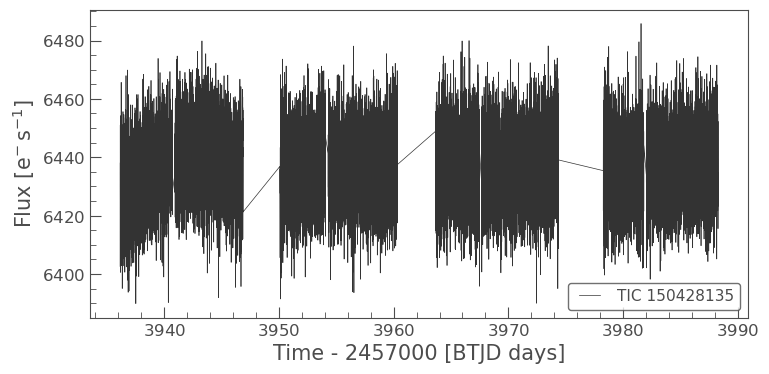

In [4]:
s97 = [lc for lc in lcc if lc.meta["SECTOR"] == 97][0].remove_nans()
t = np.array(s97.time.value, dtype=float)
gaps = np.diff(t)
for i in np.where(gaps > 0.5)[0]:
    print(f"gap of {gaps[i]:.1f} d: BTJD {t[i]:.1f} -> {t[i+1]:.1f}")
s97.plot();

In [5]:
import math

lc1 = lcc[0].remove_nans().normalize()
print("sector:", lc1.meta["SECTOR"])
f = np.array(lc1.flux.value, dtype=float)

med = np.median(f)
robust_sigma = 1.4826 * np.median(np.abs(f - med))
z = (f - med) / robust_sigma

for k in [3, 4, 5, 6]:
    n_up = int(np.sum(z > k))
    n_dn = int(np.sum(z < -k))
    expect = len(z) * 0.5 * math.erfc(k / math.sqrt(2))
    print(f">{k} sigma: {n_up:3d} high, {n_dn:3d} low  (random noise expects about {expect:.1f} per side)")

sector: 1
>3 sigma:  29 high,  17 low  (random noise expects about 24.7 per side)
>4 sigma:   0 high,   0 low  (random noise expects about 0.6 per side)
>5 sigma:   0 high,   0 low  (random noise expects about 0.0 per side)
>6 sigma:   0 high,   0 low  (random noise expects about 0.0 per side)


In [6]:
import math

rows = []
for lc in lcc:
    lc_ok = lc.remove_nans().normalize()
    f = np.array(lc_ok.flux.value, dtype=float)
    med = np.median(f)
    sig = 1.4826 * np.median(np.abs(f - med))
    z = (f - med) / sig
    rows.append({
        "sector": int(lc.meta["SECTOR"]),
        "N": len(z),
        "high>4": int(np.sum(z > 4)),
        "low<-4": int(np.sum(z < -4)),
        "high>5": int(np.sum(z > 5)),
        "low<-5": int(np.sum(z < -5)),
        "expect>4": round(len(z) * 0.5 * math.erfc(4 / math.sqrt(2)), 2),
    })

clip_table = pd.DataFrame(rows).sort_values("sector").reset_index(drop=True)
print(clip_table.to_string())
print("total high>4:", clip_table["high>4"].sum(),
      "| total low<-4:", clip_table["low<-4"].sum(),
      "| expected per side:", round(clip_table["expect>4"].sum(), 1))

    sector      N  high>4  low<-4  high>5  low<-5  expect>4
0        1  18279       0       0       0       0      0.58
1        3  12379       2       0       1       0      0.39
2        4  14435       4       0       1       0      0.46
3        5  16983       3       0       0       0      0.54
4        6  14483      13       0       2       0      0.46
5        7  16177       2       0       1       0      0.51
6        8  12849       3       0       0       0      0.41
7        9  15535       4       0       0       0      0.49
8       10  14726       3       0       0       0      0.47
9       11  13491       0       1       0       0      0.43
10      13  19437       5       3       0       0      0.62
11      27  13965       4       0       0       0      0.44
12      28  12499       3       1       0       0      0.40
13      30  15901       1       1       0       0      0.50
14      31  16491       3       1       1       0      0.52
15      33  17458       3       0       

In [7]:
clip_table.to_csv("../notes/clip_table.csv", index=False)

In [8]:
#To test robust sigma

import numpy as np

x = np.array([10, 11, 9, 10, 12, 10, 11, 30])

med = np.median(x)
dist = np.abs(x - med)
mad = np.median(dist)
robust_sigma = 1.4826 * mad
z = (x - med) / robust_sigma

print("median:", med)
print("distances from median:", dist)
print("median of distances (MAD):", mad)
print("robust sigma:", round(robust_sigma, 3))
print("z-scores:", np.round(z, 2))
print("points above 3 sigma:", x[z > 3])
print("count above 3 sigma:", int(np.sum(z > 3)))

print("ordinary std:", round(np.std(x), 2))
print("z of the 30 using ordinary mean and std:", round((30 - np.mean(x)) / np.std(x), 2))

median: 10.5
distances from median: [ 0.5  0.5  1.5  0.5  1.5  0.5  0.5 19.5]
median of distances (MAD): 0.5
robust sigma: 0.741
z-scores: [-0.67  0.67 -2.02 -0.67  2.02 -0.67  0.67 26.31]
points above 3 sigma: [30]
count above 3 sigma: 1
ordinary std: 6.53
z of the 30 using ordinary mean and std: 2.62


In [10]:
#Applying the same to Sector 1
import glob
import numpy as np
import lightkurve as lk

files = sorted(glob.glob("../data/**/*_lc.fits", recursive=True))
print(len(files), "files found")

lc1 = lk.read(files[0]).remove_nans().normalize()
print("sector:", lc1.meta["SECTOR"], "| points:", len(lc1))

f = np.array(lc1.flux.value, dtype=float)
print("first 5 flux values:", f[:5])

med = np.median(f)
print("median:", med)

dist = np.abs(f - med)
print("first 5 distances:", dist[:5])

mad = np.median(dist)
robust_sigma = 1.4826 * mad
print("MAD:", mad, "| robust sigma (ppm):", round(robust_sigma * 1e6))

z = (f - med) / robust_sigma
print("first 5 z-scores:", np.round(z[:5], 2))

print("largest z:", round(z.max(), 2), "| smallest z:", round(z.min(), 2))
print("points above 3 sigma:", int(np.sum(z > 3)), "| below -3 sigma:", int(np.sum(z < -3)))
print("ordinary std (ppm):", round(np.std(f) * 1e6))

37 files found
sector: 1 | points: 18279
first 5 flux values: [1.00111318 1.00031662 1.00087118 1.0002296  1.00151944]
median: 1.0
first 5 distances: [0.00111318 0.00031662 0.00087118 0.0002296  0.00151944]
MAD: 0.0011276602745056152 | robust sigma (ppm): 1672
first 5 z-scores: [0.67 0.19 0.52 0.14 0.91]
largest z: 3.95 | smallest z: -3.68
points above 3 sigma: 29 | below -3 sigma: 17
ordinary std (ppm): 1656


In [11]:
#Applying this to huge toy data
import numpy as np
import pandas as pd

toy = {
    "A": np.array([10, 11, 9, 10, 12, 10, 11, 30]),
    "B": np.array([5, 6, 5, 4, 5, 6, 4, 5]),
    "C": np.array([100, 98, 102, 101, 99, 100, 140, 100]),
}

rows = []
for name, x in toy.items():
    med = np.median(x)
    sig = 1.4826 * np.median(np.abs(x - med))
    z = (x - med) / sig
    print("working on", name, "| median", med, "| robust sigma", round(sig, 2))
    rows.append({
        "name": name,
        "N": len(x),
        "high>3": int(np.sum(z > 3)),
        "low<-3": int(np.sum(z < -3)),
    })
    print("rows so far:", len(rows))

table = pd.DataFrame(rows)
print(table)

working on A | median 10.5 | robust sigma 0.74
rows so far: 1
working on B | median 5.0 | robust sigma 0.74
rows so far: 2
working on C | median 100.0 | robust sigma 1.48
rows so far: 3
  name  N  high>3  low<-3
0    A  8       1       0
1    B  8       0       0
2    C  8       1       0


In [12]:
#Checking sector 6

import glob
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk

files = sorted(glob.glob("../data/**/*_lc.fits", recursive=True))
lcc = lk.LightCurveCollection([lk.read(f) for f in files])

s6 = [lc for lc in lcc if lc.meta["SECTOR"] == 6][0].remove_nans().normalize()
f = np.array(s6.flux.value, dtype=float)
t = np.array(s6.time.value, dtype=float)

med = np.median(f)
sig = 1.4826 * np.median(np.abs(f - med))
z = (f - med) / sig

hi = np.where(z > 4)[0]
print("points above 4 sigma:", len(hi))
for i in hi:
    print(f"BTJD {t[i]:.4f}  z = {z[i]:.1f}  index {i}")
print("index gaps between flagged points:", np.diff(hi))

points above 4 sigma: 13
BTJD 1468.9304  z = 4.0  index 467
BTJD 1469.1679  z = 4.2  index 638
BTJD 1469.1943  z = 4.7  index 657
BTJD 1476.1791  z = 5.3  index 5561
BTJD 1478.5694  z = 4.0  index 6274
BTJD 1478.6708  z = 4.6  index 6337
BTJD 1479.0430  z = 4.1  index 6590
BTJD 1479.0444  z = 4.0  index 6591
BTJD 1483.1708  z = 4.4  index 9549
BTJD 1483.5583  z = 4.9  index 9828
BTJD 1486.0555  z = 4.2  index 11617
BTJD 1487.0486  z = 5.1  index 12332
BTJD 1487.3458  z = 4.1  index 12546
index gaps between flagged points: [ 171   19 4904  713   63  253    1 2958  279 1789  715  214]


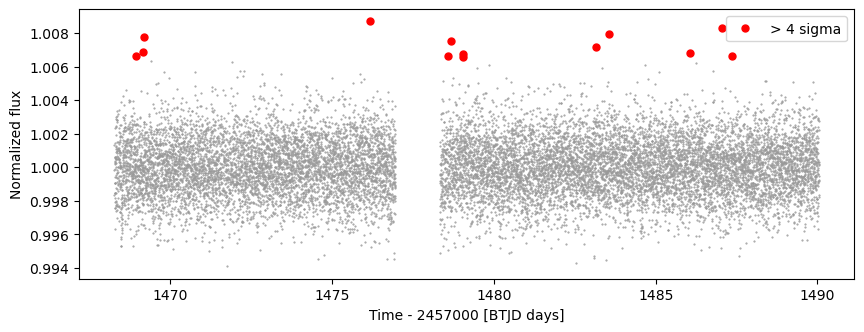

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, f, ".", ms=1, color="0.6")
ax.plot(t[hi], f[hi], "o", color="red", ms=5, label="> 4 sigma")
ax.set_xlabel("Time - 2457000 [BTJD days]")
ax.set_ylabel("Normalized flux")
ax.legend()
plt.show()

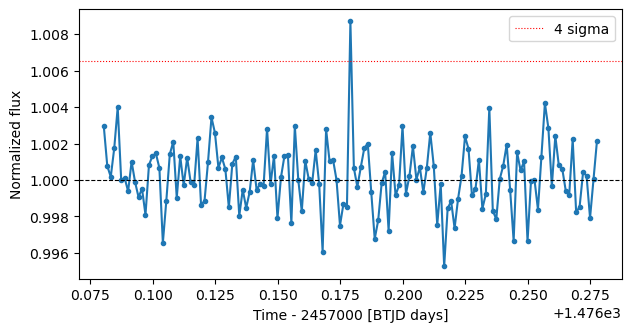

In [14]:
j = hi[np.argmax(z[hi])]
window = (t > t[j] - 0.1) & (t < t[j] + 0.1)

plt.figure(figsize=(7, 3.5))
plt.plot(t[window], f[window], "o-", ms=3)
plt.axhline(med, color="k", ls="--", lw=0.8)
plt.axhline(med + 4 * sig, color="r", ls=":", lw=0.8, label="4 sigma")
plt.xlabel("Time - 2457000 [BTJD days]")
plt.ylabel("Normalized flux")
plt.legend()
plt.show()

In [16]:
#Now cleaning the data by removing 4 sigma points in all sectors

def clean_sector(lc, k=4.0):
    lc = lc.remove_nans().normalize()
    f = np.array(lc.flux.value, dtype=float)
    med = np.median(f)
    sig = 1.4826 * np.median(np.abs(f - med))
    z = (f - med) / sig
    keep = z <= k
    return lc[keep], int(np.sum(~keep))

In [17]:
cleaned = []
rows = []
for lc in lcc:
    lc_c, n_removed = clean_sector(lc)
    cleaned.append(lc_c)
    rows.append({
        "sector": int(lc.meta["SECTOR"]),
        "n_after_nan": len(lc.remove_nans()),
        "n_removed": n_removed,
        "n_clean": len(lc_c),
    })

clean_table = pd.DataFrame(rows).sort_values("sector").reset_index(drop=True)
print(clean_table.to_string())
print("total removed:", clean_table["n_removed"].sum(), "| total kept:", clean_table["n_clean"].sum())

    sector  n_after_nan  n_removed  n_clean
0        1        18279          0    18279
1        3        12379          2    12377
2        4        14435          4    14431
3        5        16983          3    16980
4        6        14483         13    14470
5        7        16177          2    16175
6        8        12849          3    12846
7        9        15535          4    15531
8       10        14726          3    14723
9       11        13491          0    13491
10      13        19437          5    19432
11      27        13965          4    13961
12      28        12499          3    12496
13      30        15901          1    15900
14      31        16491          3    16488
15      33        17458          3    17455
16      34        16758          3    16755
17      35        13607          6    13601
18      36        15209          6    15203
19      37        14747          4    14743
20      38        17925          7    17918
21      61        15141         

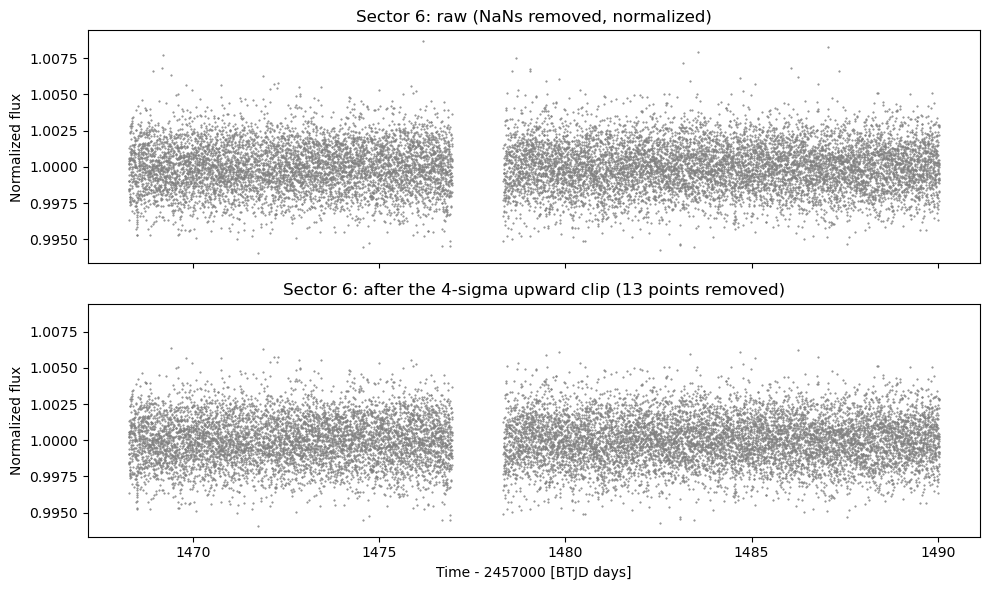

In [19]:
#Raw vs Clean (Safe) Sector 6

import matplotlib.pyplot as plt

sectors = [int(lc.meta["SECTOR"]) for lc in lcc]
idx = sectors.index(6)
raw6 = lcc[idx].remove_nans().normalize()
cl6 = cleaned[idx]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
axes[0].plot(raw6.time.value, raw6.flux.value, ".", ms=1, color="0.5")
axes[0].set_title("Sector 6: raw (NaNs removed, normalized)")
axes[1].plot(cl6.time.value, cl6.flux.value, ".", ms=1, color="0.5")
axes[1].set_title("Sector 6: after the 4-sigma upward clip (13 points removed)")
axes[1].set_xlabel("Time - 2457000 [BTJD days]")
for ax in axes:
    ax.set_ylabel("Normalized flux")
fig.tight_layout()
fig.savefig("../figures/sector6_raw_vs_clean.png", dpi=150)
plt.show()

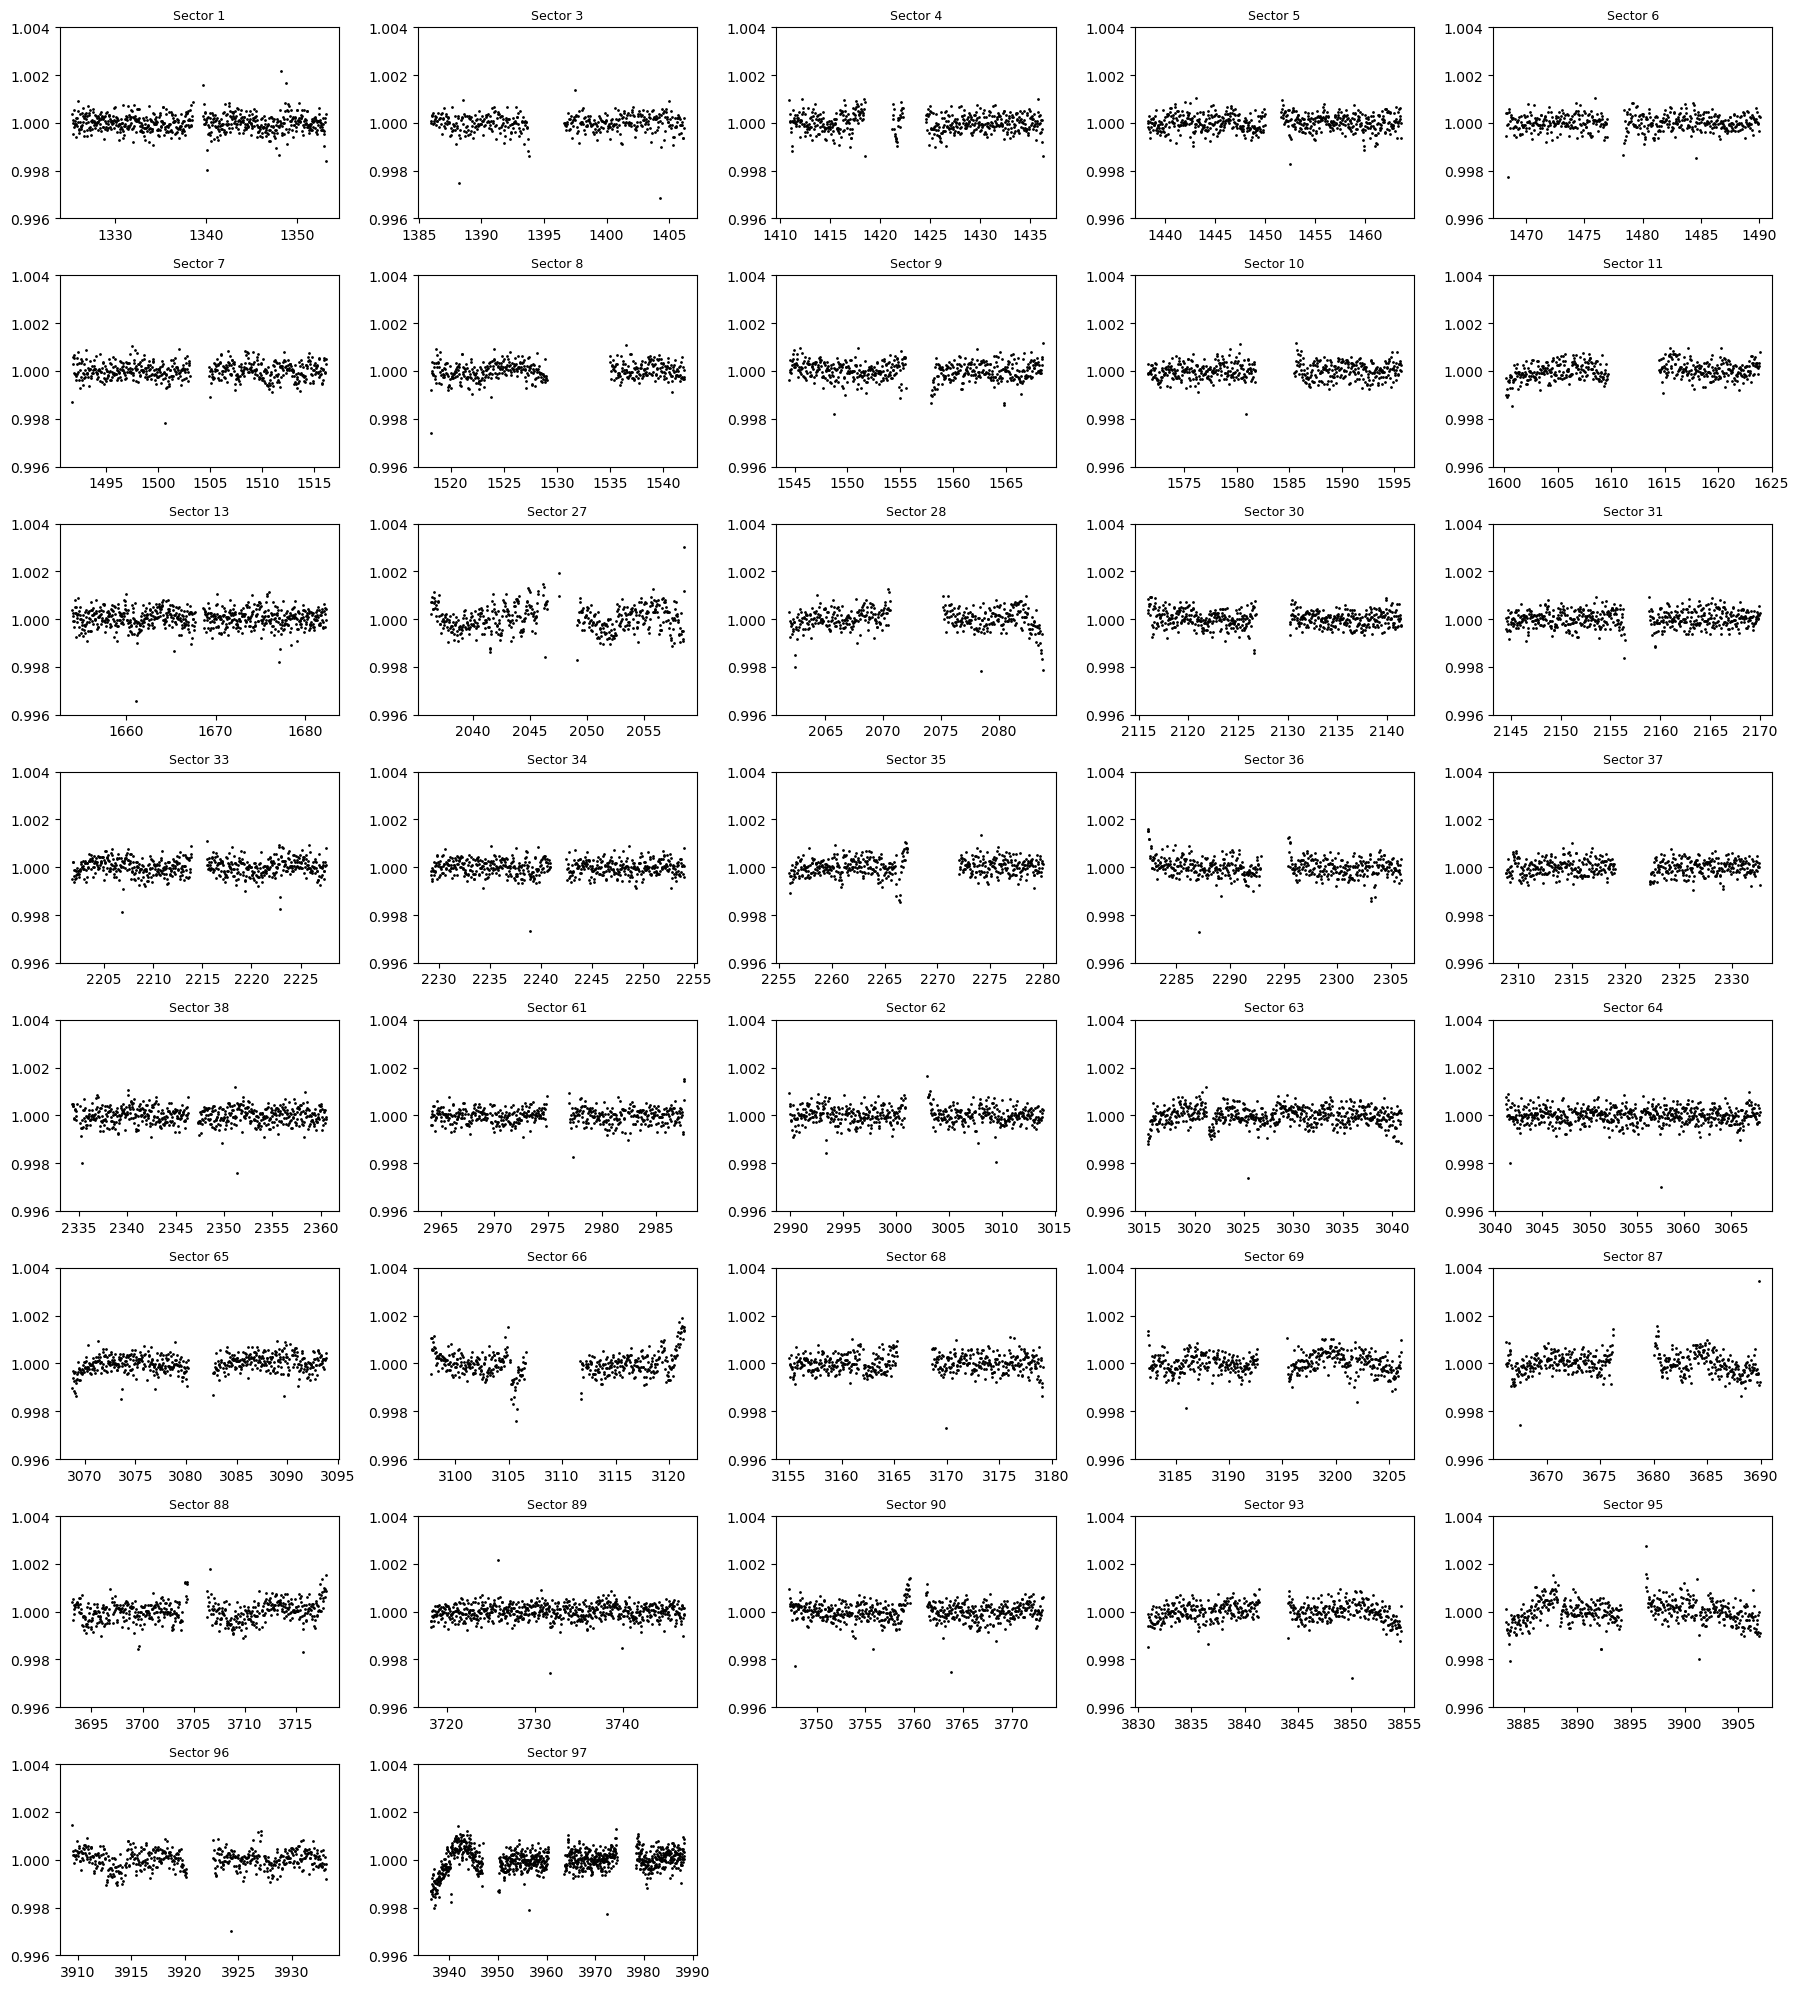

In [20]:
#All sectors

import astropy.units as u

fig, axes = plt.subplots(8, 5, figsize=(18, 20))
axes = axes.ravel()
for ax, lc_c, s in zip(axes, cleaned, sectors):
    b = lc_c.bin(time_bin_size=60*u.min).remove_nans()
    ax.plot(b.time.value, b.flux.value, ".", ms=2, color="k")
    ax.set_title(f"Sector {s}", fontsize=9)
    ax.set_ylim(0.996, 1.004)
for ax in axes[len(cleaned):]:
    ax.axis("off")
fig.tight_layout()
fig.savefig("../figures/all_sectors_cleaned_1h_bins.png", dpi=120)
plt.show()

In [21]:
#saving the cleaned data

import os
os.makedirs("../data/cleaned", exist_ok=True)

for lc_c, s in zip(cleaned, sectors):
    np.savez_compressed(
        f"../data/cleaned/sector_{s:03d}.npz",
        time=np.array(lc_c.time.value, dtype=float),
        flux=np.array(lc_c.flux.value, dtype=float),
        flux_err=np.array(lc_c.flux_err.value, dtype=float),
    )
print(sorted(os.listdir("../data/cleaned"))[:3], "...", len(os.listdir("../data/cleaned")), "files")

['sector_001.npz', 'sector_003.npz', 'sector_004.npz'] ... 37 files


In [22]:
#Gap table

rows = []
for lc_c, s in zip(cleaned, sectors):
    t = np.array(lc_c.time.value, dtype=float)
    dt = np.diff(t)
    big = dt[dt > 0.5]
    rows.append({
        "sector": s,
        "span_d": round(t[-1] - t[0], 1),
        "good_d": round(len(t) * 2 / 1440, 1),
        "gaps>0.5d": len(big),
        "largest_gap_d": round(float(big.max()), 1) if len(big) else 0.0,
        "gaps>0.1d": int(np.sum(dt > 0.1)),
    })

gap_table = pd.DataFrame(rows).sort_values("sector").reset_index(drop=True)
print(gap_table.to_string())

    sector  span_d  good_d  gaps>0.5d  largest_gap_d  gaps>0.1d
0        1    27.9    25.4          1            1.1          1
1        3    20.3    17.2          1            2.9          1
2        4    25.4    20.0          2            2.7          2
3        5    25.4    23.6          1            1.6          1
4        6    21.8    20.1          1            1.4          1
5        7    24.4    22.5          1            1.8          1
6        8    23.9    17.8          1            5.9          1
7        9    24.0    21.6          1            2.4          1
8       10    24.2    20.4          1            3.7          1
9       11    23.7    18.7          1            4.8          1
10      13    28.4    27.0          1            0.9          1
11      27    22.3    19.4          2            1.6          3
12      28    22.0    17.4          1            4.6          1
13      30    25.6    22.1          1            3.4          1
14      31    25.4    22.9          1   

In [23]:
clean_table.to_csv("../notes/clean_table.csv", index=False)
gap_table.to_csv("../notes/gap_table.csv", index=False)   

In [24]:
import numpy as np

G = 6.674e-11                    # gravitational constant (SI units)
M, R, Teff = 0.416, 0.420, 3480  # mass and radius in solar units, Teff in K

print("density from M and R:", round(M / R**3, 2), "rho_sun =", round(M / R**3 * 1.41, 2), "g/cm3  (paper: 8.0)")
print("luminosity from R and Teff:", round(R**2 * (Teff / 5772)**4, 4), "Lsun  (paper: 0.0233)")
print("log g from M and R:", round(4.438 + np.log10(M) - 2 * np.log10(R), 2), " (paper: 4.81)")

rho_si = 8.0 * 1000              # 8.0 g/cm3 converted to kg/m3
planets = {
    "b": dict(P=9.97701,   k=0.0221, b=0.20,  aR=34.8, T14=2.15),
    "c": dict(P=16.051098, k=0.0574, b=0.904, aR=47.8, T14=1.41),
    "d": dict(P=37.4260,   k=0.0262, b=0.40,  aR=84.0, T14=3.21),
}

for name, p in planets.items():
    P_s = p["P"] * 86400                                        # period in seconds
    aR_from_rho = (G * rho_si * P_s**2 / (3 * np.pi)) ** (1/3)  # Winn eq. 30
    sin_i = np.sqrt(1 - (p["b"] / p["aR"])**2)
    T14 = (p["P"] * 24 / np.pi) * np.arcsin(
        np.sqrt((1 + p["k"])**2 - p["b"]**2) / (p["aR"] * sin_i))  # Winn eq. 14, in hours
    Rp = p["k"] * R * 109.1                                     # Earth radii per solar radius = 109.1
    print(f"{name}: a/R* from density {aR_from_rho:.1f} (paper {p['aR']}) | "
          f"T14 {T14:.2f} h (paper {p['T14']}) | Rp {Rp:.2f} Re | depth k^2 {p['k']**2 * 1e6:.0f} ppm")

density from M and R: 5.61 rho_sun = 7.92 g/cm3  (paper: 8.0)
luminosity from R and Teff: 0.0233 Lsun  (paper: 0.0233)
log g from M and R: 4.81  (paper: 4.81)
b: a/R* from density 34.8 (paper 34.8) | T14 2.20 h (paper 2.15) | Rp 1.01 Re | depth k^2 488 ppm
c: a/R* from density 47.8 (paper 47.8) | T14 1.41 h (paper 1.41) | Rp 2.63 Re | depth k^2 3295 ppm
d: a/R* from density 84.0 (paper 84.0) | T14 3.22 h (paper 3.21) | Rp 1.20 Re | depth k^2 686 ppm


In [29]:
#importing saved values

import sys
sys.path.append("../src")
from toi700_params import STAR, PLANETS

print(PLANETS["d"]["P"], PLANETS["d"]["T0"])

37.426 1330.4737


In [31]:
import sys, importlib
sys.path.append("../src")
import toi700_params
importlib.reload(toi700_params)
from toi700_params import PLANETS

print(PLANETS["b"].keys())

dict_keys(['P', 'P_err', 'T0', 'T0_err', 'T14_h', 'T14_err', 'k', 'impact', 'a_over_R', 'Rp_earth'])


In [32]:
t_mid = 3960.0
for name, p in PLANETS.items():
    n = (t_mid - p["T0"]) / p["P"]
    sigma_h = n * max(p["P_err"]) * 24
    print(f"{name}: {n:.1f} orbits after T0 | timing uncertainty about {sigma_h:.1f} h | transit lasts {p['T14_h']} h")

b: 263.5 orbits after T0 | timing uncertainty about 1.8 h | transit lasts 2.15 h
c: 163.2 orbits after T0 | timing uncertainty about 0.4 h | transit lasts 1.41 h
d: 70.3 orbits after T0 | timing uncertainty about 1.7 h | transit lasts 3.21 h
